# Memphis Police Department — Flock Search Audit Analysis
Audit coverage, stated reasons, search types, timing, and scope, for Memphis Police Department. These logs describe recorded searches, not crimes, stops, or outcomes.

In [1]:
import csv, json, re, math, statistics
from collections import Counter, defaultdict
from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo
from html import escape
from IPython.display import HTML, SVG, display
from categorized_output.memphis_visuals import percent_chart, series_chart, percent_chart_plain, series_chart_plain

DATA_PATH = Path("new_normalizations/Memphis_categorized.csv")
OUT_DIR = Path("analysis_output/memphis")
LOCAL_TZ = ZoneInfo("America/Chicago")
MIN_N = 100

def table(headers, data, limit=25):
    data = list(data)
    body = ''.join('<tr>' + ''.join(f'<td>{escape(str(x))}</td>' for x in row) + '</tr>' for row in data[:limit])
    display(HTML('<table><thead><tr>' + ''.join(f'<th>{escape(h)}</th>' for h in headers) + '</tr></thead><tbody>' + body + '</tbody></table>'))
    if len(data) > limit: print(f"Showing {limit} of {len(data):,} rows.")

def parse_time(value):
    try: return datetime.fromisoformat(value.replace('Z', '+00:00')).astimezone(LOCAL_TZ)
    except (ValueError, AttributeError): return None

def source_files(row):
    try: return {s.get('filename') or s.get('source_url', '(unnamed)') for s in json.loads(row['sources'] or '[]')}
    except (ValueError, TypeError): return set()

# Prepare the shared analysis data.
with DATA_PATH.open(newline='', encoding='utf-8-sig') as f:
    raw = list(csv.DictReader(f))
valid = [r for r in raw if parse_time(r['search_time_utc'])]
invalid = [r for r in raw if not parse_time(r['search_time_utc'])]
KEY = ['search_time_utc', 'start_timeframe_utc', 'end_timeframe_utc', 'search_type']
groups = defaultdict(list)
for r in valid: groups[tuple(r[k] for k in KEY)].append(r)
records, conflicts = [], []
for key, copies in groups.items():
    reasons = {re.sub(r'\s+', ' ', r['reason'].strip().casefold()) for r in copies if r['reason'].strip()}
    if len(reasons) > 1:
        conflicts.append((key, copies))
        partitions = [[r] for r in copies]  # preserve every row when reason texts conflict
    else:
        partitions = [copies]
    for partition in partitions:
        ranked = sorted(partition, key=lambda r: (bool(r['reason'].strip()), sum(bool(v.strip()) for v in r.values())), reverse=True)
        row = {k: next((r[k] for r in ranked if r[k].strip()), '') for k in valid[0]}
        row['_sources'] = set().union(*(source_files(r) for r in partition))
        row['_copies'] = len(partition)
        row['_time'] = parse_time(row['search_time_utc'])
        row['_month'] = row['_time'].strftime('%Y-%m')
        row['_reason'] = re.sub(r'\s+', ' ', row['reason'].upper().replace('+', ' ')).strip()
        row['_category'] = row['reason_category'] if row['reason'].strip() else 'Reason not recorded'
        records.append(row)
records.sort(key=lambda r: r['_time'])
rows, total = records, len(records)
assert sum(r["_copies"] for r in records) == len(valid)


## 1. Coverage and search volume
Monthly counts are lower bounds shaped by obtained audits; source-file counts and blank-reason shares help assess coverage. Boundary months are partial, and dates use Memphis Central time.

Observed coverage: 2022-05-13 to 2025-02-03; 283 source files.
Busiest recorded day: ('2025-01-27', 397); median per active day: 7.


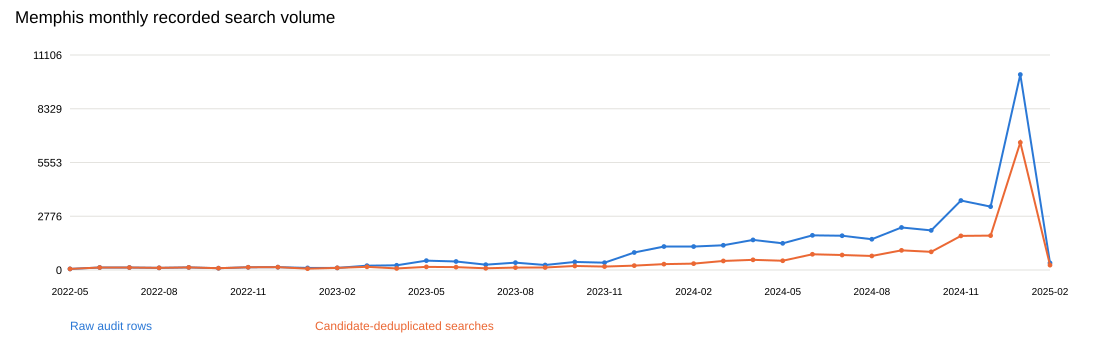

Month,Raw rows,Searches,Source files,% without reason
2022-05,56,56,1,0.0%
2022-06,129,129,1,0.0%
2022-07,128,128,1,0.0%
2022-08,111,111,1,0.0%
2022-09,134,134,1,0.0%
2022-10,93,93,1,0.0%
2022-11,141,141,1,0.0%
2022-12,147,147,1,0.0%
2023-01,107,69,4,0.0%
2023-02,109,109,5,0.0%


In [2]:
first, last = records[0]['_time'], records[-1]['_time']
months=[]
y,m=first.year,first.month
while (y,m) <= (last.year,last.month):
    months.append(f'{y:04d}-{m:02d}')
    y,m=(y+1,1) if m==12 else (y,m+1)
monthly=Counter(r['_month'] for r in records)
raw_monthly=Counter(parse_time(r['search_time_utc']).strftime('%Y-%m') for r in valid)
reason_monthly=Counter(r['_month'] for r in records if r['reason'].strip())
sources_by_month={m:set().union(*(r['_sources'] for r in records if r['_month']==m)) for m in months}
coverage=[(m,raw_monthly[m],monthly[m],len(sources_by_month[m]),f'{(monthly[m]-reason_monthly[m])/monthly[m]:.1%}' if monthly[m] else 'n/a') for m in months]
print(f"Observed coverage: {first:%Y-%m-%d} to {last:%Y-%m-%d}; {len(set().union(*(r['_sources'] for r in records)))} source files.")
series_chart_plain({'Raw audit rows':dict(raw_monthly),'Candidate-deduplicated searches':dict(monthly)}, 'Memphis monthly recorded search volume', interpretation='The later increase may combine more searches with broader audit coverage. Repeated copies in overlapping audits also help explain why the raw-row line rises above the deduplicated count.')
table(['Month','Raw rows','Searches','Source files','% without reason'],coverage,limit=len(months))
daily=Counter(r['_time'].date().isoformat() for r in records)
print(f"Busiest recorded day: {daily.most_common(1)[0]}; median per active day: {statistics.median(daily.values()):.0f}.")

## 2. Stated reasons and monthly shares
Use normalized reason categories, with blank reasons shown separately. Monthly reasoned-search shares are masked below 100 observations; generic investigation is not a specific offense.

Reasoned-search denominator: 19,338; masked months: ['2022-05', '2022-10', '2023-01', '2023-04', '2023-07'].


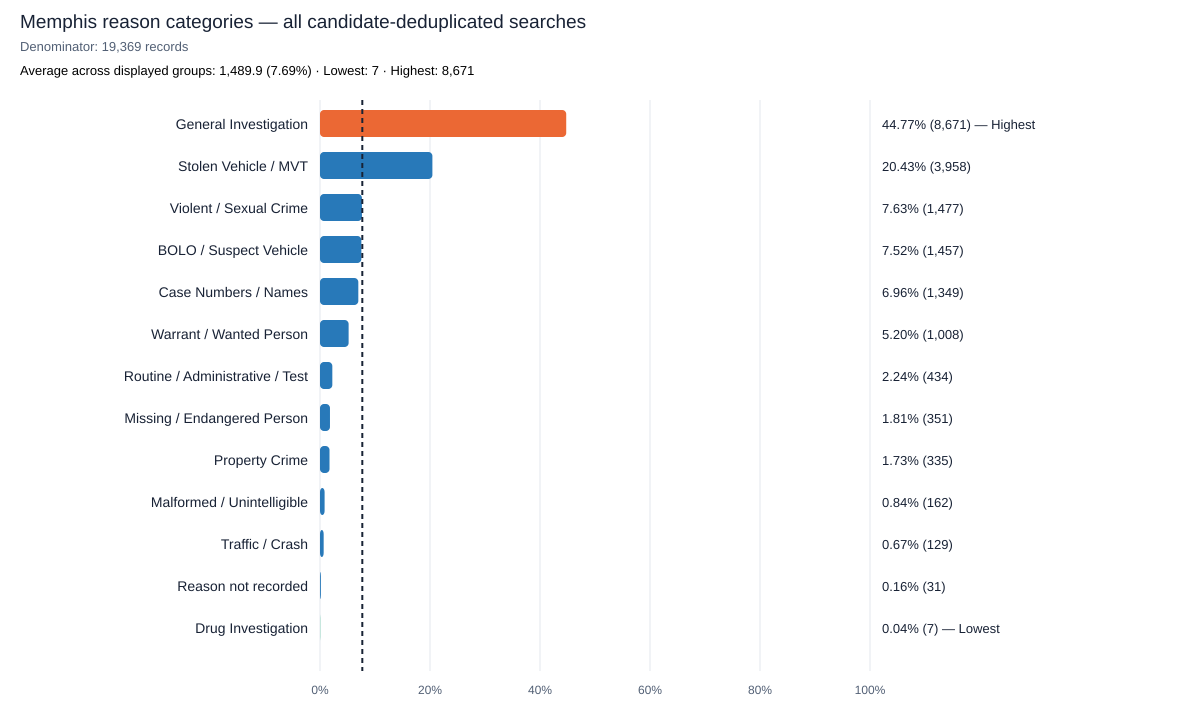

Group,Records,Percent
General Investigation,"8,671",44.77%
Stolen Vehicle / MVT,"3,958",20.43%
Violent / Sexual Crime,"1,477",7.63%
BOLO / Suspect Vehicle,"1,457",7.52%
Case Numbers / Names,"1,349",6.96%
Warrant / Wanted Person,"1,008",5.20%
Routine / Administrative / Test,434,2.24%
Missing / Endangered Person,351,1.81%
Property Crime,335,1.73%
Malformed / Unintelligible,162,0.84%


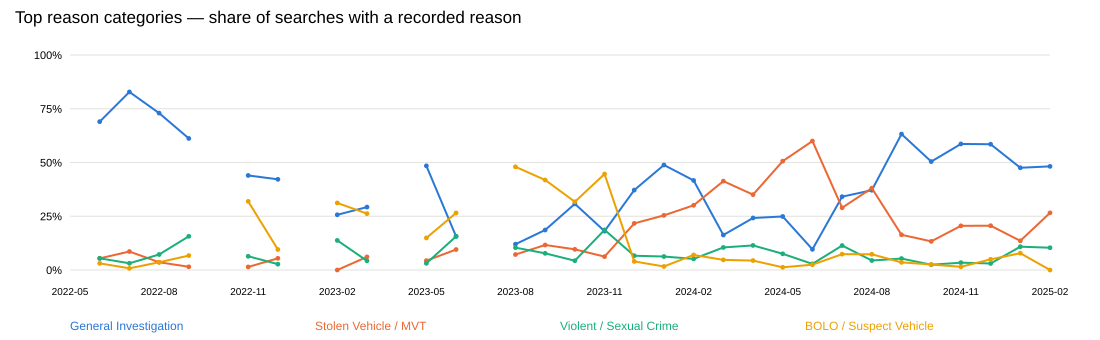

In [3]:
category_counts = Counter(r['_category'] for r in records)
percent_chart(dict(category_counts.most_common()), 'Memphis reason categories — all candidate-deduplicated searches', total, interpretation='Broad investigation labels may be used as a convenient catch-all, which could explain their large share. The mix reflects how officers describe searches as well as what they are searching for.')
reasoned=[r for r in records if r['reason'].strip()]
reasoned_categories=Counter(r['_category'] for r in reasoned)
leaders=[c for c,n in reasoned_categories.most_common(4)]
category_month=Counter((r['_month'],r['_category']) for r in reasoned)
shares={c:{m:100*category_month[m,c]/reason_monthly[m] if reason_monthly[m]>=MIN_N else None for m in months} for c in leaders}
series_chart_plain(shares, 'Top reason categories — share of searches with a recorded reason', percent=True, interpretation='Changing shares may reflect shifts in investigative work, wording habits, or which source audits cover each month. A category gaining share does not necessarily mean more searches in that category.')
print(f"Reasoned-search denominator: {len(reasoned):,}; masked months: {[m for m in months if reason_monthly[m]<MIN_N]}.")

## 3. Common reasons, patrol, and tests
Show recurring labels and explicit patrol/test wording from Memphis records. These flags describe text, not whether a search was justified.

In [4]:
top_reasons=Counter(r['_reason'] for r in reasoned)
table(['Normalized reason','Searches','Share of reasoned searches'],[(s,n,f'{n/len(reasoned):.1%}') for s,n in top_reasons.most_common(25)])
text_patterns={'Explicit patrol':r'\bPATROL\b', 'Explicit test / training':r'\b(?:TEST|TESTING|TRAINING)\b', 'Generic investigation only':r'^(?:INVESTIGATION|INV|INVEST|LE)$'}
text_flags={label:[r for r in records if re.search(pattern,r['_reason'])] for label,pattern in text_patterns.items()}
table(['Text flag (may overlap)','Searches','Share of all searches'],[(label,len(rs),f'{len(rs)/total:.1%}') for label,rs in text_flags.items()])
table(['Observed test / training reason','Searches'],Counter(r['_reason'] for r in text_flags['Explicit test / training']).most_common())

Normalized reason,Searches,Share of reasoned searches
INVESTIGATION,6443,33.3%
STOLEN,1999,10.3%
MVT,1068,5.5%
INV,1032,5.3%
ATL,836,4.3%
STOLEN VEHICLE,625,3.2%
LE,420,2.2%
WARRANT,390,2.0%
CARJACKING,350,1.8%
HOMICIDE,293,1.5%


Text flag (may overlap),Searches,Share of all searches
Explicit patrol,46,0.2%
Explicit test / training,33,0.2%
Generic investigation only,8052,41.6%


Observed test / training reason,Searches
TEST,28
TRAINING,2
INVESTIGATION TEST,1
TEST LOOKUP,1
MPD TRAINING,1


## 4. Lookup versus search
Combine mobile and desktop labels for the overall mix, while retaining convoy and unexpected types. The monthly mobile share measures interface labels, not search purpose.

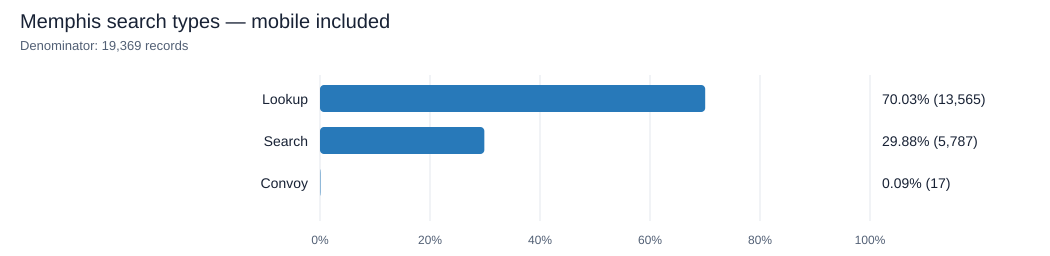

Group,Records,Percent
Lookup,"13,565",70.03%
Search,"5,787",29.88%
Convoy,17,0.09%


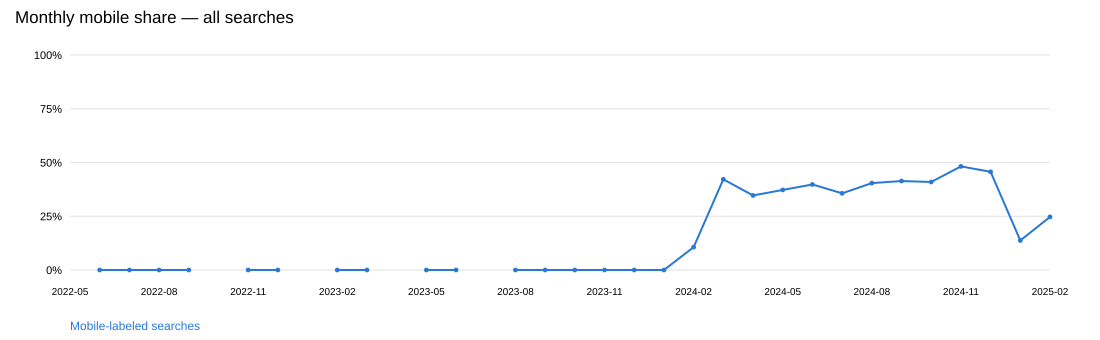

In [5]:
type_counts=Counter(re.sub(r'\s*-\s*mobile$', '',r['search_type'].lower()).title() or 'Unspecified' for r in records)
percent_chart_plain(dict(type_counts.most_common()), 'Memphis search types — mobile included', total, interpretation='The dominance of lookup may reflect frequent checks on known vehicles rather than broader exploratory searches. The interface labels alone do not confirm the purpose of those checks.')
mobile_monthly=Counter(r['_month'] for r in records if 'mobile' in r['search_type'].lower())
series_chart_plain({'Mobile-labeled searches':{m:100*mobile_monthly[m]/monthly[m] if monthly[m]>=MIN_N else None for m in months}}, 'Monthly mobile share — all searches', percent=True, interpretation='Changes in mobile share could reflect changes in field use, device access, or audit labeling. A higher mobile share does not by itself show that overall searching increased.')

## 5. Blank reasons before and after deduplication
Only empty or whitespace-only text counts as blank; UNKNOWN and case numbers remain nonblank. Missing text may reflect source-audit omissions rather than officer entry behavior.

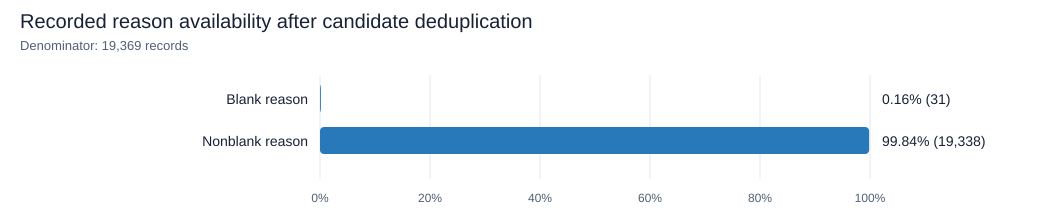

Group,Records,Percent
Blank reason,31,0.16%
Nonblank reason,"19,338",99.84%


Dataset,Blank reasons,Denominator,Blank share
Raw valid audit rows,10839,38500,28.2%
Candidate-deduplicated searches,31,19369,0.2%


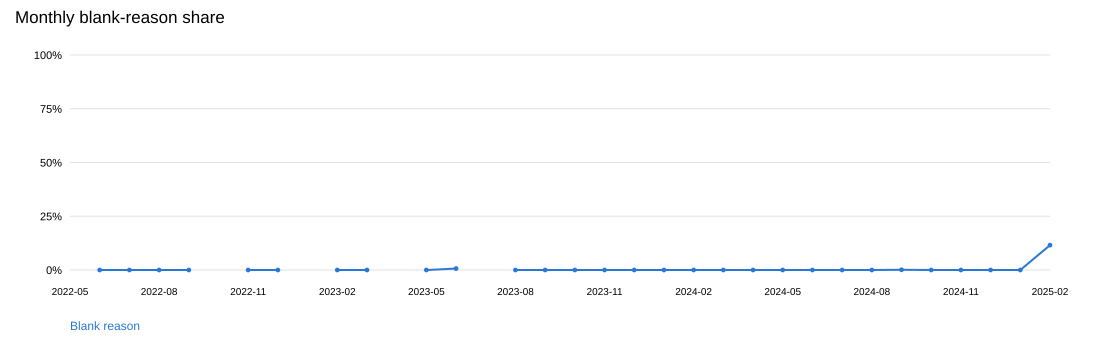

In [6]:
raw_blank=sum(not r['reason'].strip() for r in valid)
blank_count=sum(not r['reason'].strip() for r in records)
percent_chart_plain({'Blank reason':blank_count,'Nonblank reason':total-blank_count}, 'Recorded reason availability after candidate deduplication', total, interpretation='Many blank audit entries have a matching copy with a recorded reason, so merging copies leaves very few blanks. This suggests source omissions explain much of the missing text in the raw rows.')
table(['Dataset','Blank reasons','Denominator','Blank share'],[('Raw valid audit rows',raw_blank,len(valid),f'{raw_blank/len(valid):.1%}'),('Candidate-deduplicated searches',blank_count,total,f'{blank_count/total:.1%}')])
series_chart_plain({'Blank reason':{m:100*(monthly[m]-reason_monthly[m])/monthly[m] if monthly[m]>=MIN_N else None for m in months}}, 'Monthly blank-reason share',percent=True, interpretation='The remaining monthly variation may depend on whether another audit supplies the missing reason. Small numbers of unresolved blanks can also produce visible changes when monthly totals are low.')

## 6. Misspellings
Compare misspelled and not misspelled reasons among nonblank entries using the listed spelling rules. Blank entries are excluded.

Misspelled: 395 / 19,338 nonblank entries = 2.04%


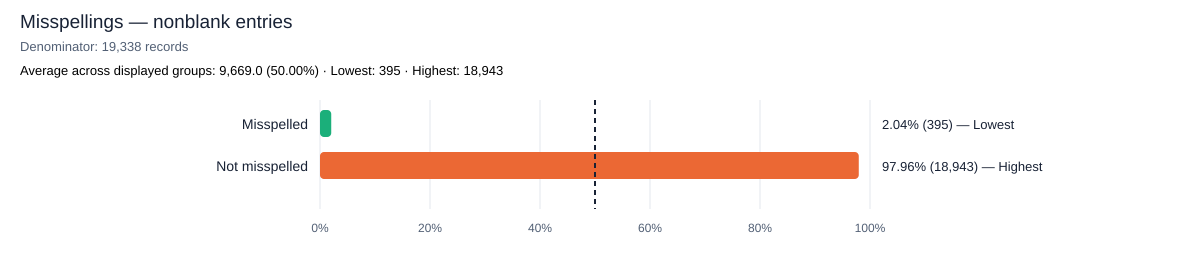

Group,Records,Percent
Misspelled,395,2.04%
Not misspelled,"18,943",97.96%


Reason,Records,Matched rule
Investigaton,74,INVESTIGATION
invetigation,30,INVESTIGATION
Carjaked,25,CARJACKED
Inestigation,15,INVESTIGATION
ivestigation,12,INVESTIGATION
Invesigation,11,INVESTIGATION
investgation,11,INVESTIGATION
investigstion,10,INVESTIGATION
ROBERRY VEHICLE,10,ROBBERY
Stone car,10,STOLEN CAR


Misspelling,Correct form,Records with misspelling,Records with correct form,Misspelling %
INVESTIGATON,INVESTIGATION,77,"6,802",1.12%
INVETIGATION,INVESTIGATION,34,"6,802",0.50%
CARJAKED,CARJACKED,25,36,40.98%
INVESIGATION,INVESTIGATION,19,"6,802",0.28%
IVESTIGATION,INVESTIGATION,19,"6,802",0.28%
INESTIGATION,INVESTIGATION,17,"6,802",0.25%
ROBERRY,ROBBERY,17,275,5.82%
INVESTGATION,INVESTIGATION,11,"6,802",0.16%
INVESTIGSTION,INVESTIGATION,10,"6,802",0.15%
STONE CAR,STOLEN CAR,10,30,25.00%


In [7]:
# Conservative, editable typo rules based on the reason text in this dataset.
# This is a rule-based estimate, not a comprehensive spelling assessment.
# Abbreviations (INV, MVT, ATL, LE), case numbers, and blank reasons are not typos.
# Plus signs are treated as word separators; the original CSV is never changed.
TYPO_GROUPS = {
    "INVESTIGATION": "INESTIGATION INETIGATION INVESIGATION INVESIGTION INVESTATION INVESTGAION INVESTGATION INVESTIATION INVESTIGAION INVESTIGAITON INVESTIGAQTION INVESTIGASTION INVESTIGATIN INVESTIGATON INVESTIGSTION INVESTIGTION INVESTIHATION INVESTITAGION INVETIGATION INVRSTIGATION INVSIGATION INVSTI9GATION INVSTIATION INVSTIGATION IVESTAGATION IVESTIGATIO IVESTIGATION NVESTIGATION",
    "INVESTIGATE": "INVESTGATE",
    "ROBBERY": "ROBBEERY ROBBERRY ROBERRY ROBERY",
    "CARJACKED": "CAEJACKED CARJAKED",
    "CARJACKING": "CARJCKING",
    "HOMICIDE": "HOMCIDE HOMICDE HOMOCIDE",
    "KIDNAPPING": "KDNAPPING KINAPPING",
    "MISSING": "MISSNG",
    "PERSON": "PERAON",
    "ASSAULT": "ASAULT",
    "SUSPECT": "SUSPET SUSPEVT SUSPPECT",
    "SUSPICIOUS": "SUSPICIUS",
    "STOLEN": "STOEN STOOEN",
    "VEHICLE": "VEHCILE VEHCLE VEHICE VEHICEL VEHLCE",
    "SHOPLIFTER": "SHIPLIFTER",
    "SHOOTING": "SHOTING",
    "BURGLARY": "BUGLARY",
    "WARRANT": "WARRANTT",
    "WARRANTS": "WARTRANTS",
}
TYPO_CORRECTIONS = {typo: correction
                    for correction, variants in TYPO_GROUPS.items()
                    for typo in variants.split()}
# Phrase rules capture errors that are otherwise valid words.
PHRASE_CORRECTIONS = {"HIT ADN UN": "HIT AND RUN", "STONE CAR": "STOLEN CAR"}

def normalize_reason(reason):
    return " ".join(reason.upper().replace("+", " ").split())

def spelling_matches(reason):
    text = normalize_reason(reason)
    tokens = re.findall(r"[A-Z0-9]+", text)
    matches = [f"{TYPO_CORRECTIONS[token]}"
               for token in tokens if token in TYPO_CORRECTIONS]
    if text in PHRASE_CORRECTIONS:
        matches.append(f"{PHRASE_CORRECTIONS[text]}")
    return sorted(set(matches))

# Count each nonblank record once, even if its reason has multiple misspellings.
nonblank_rows = [row for row in rows if row["reason"].strip()]
nonblank_count = len(nonblank_rows)
flagged = [row for row in nonblank_rows if spelling_matches(row["reason"])]
spelling_counts = {
    "Misspelled": len(flagged),
    "Not misspelled": nonblank_count - len(flagged),
}
if nonblank_count:
    percent_chart(spelling_counts, "Misspellings — nonblank entries", nonblank_count, interpretation='Short, repeated reason labels may help keep the misspelled share low, while free-text entry leaves room for typing errors. The listed rules capture specific variants, so unlisted errors would not appear here.')
    print(f"Misspelled: {len(flagged):,} / {nonblank_count:,} nonblank entries = {100 * len(flagged) / nonblank_count:.2f}%")
else:
    print("No nonblank entries to compare.")

# Audit table: inspect exactly which reason values were counted.
flagged_reasons = Counter(row["reason"] for row in flagged)
audit_rows = [f"<tr><td>{escape(reason)}</td><td>{count:,}</td>"
              f"<td>{escape('; '.join(spelling_matches(reason)))}</td></tr>"
              for reason, count in flagged_reasons.most_common(20)]
display(HTML("<h4>Top 20 misspelled reasons and corrections</h4>"
             "<table><thead><tr><th>Reason</th><th>Records</th><th>Matched rule</th></tr></thead>"
             "<tbody>" + "".join(audit_rows) + "</tbody></table>"))


# Compare every observed typo with its corresponding correctly spelled form.
# Counts are records containing the word, including words inside longer reasons.
# Each form counts at most once per record. Phrase rules use the same exact
# normalized-reason matching as spelling_matches above.
word_record_counts = Counter()
phrase_record_counts = Counter()
for row in nonblank_rows:
    text = normalize_reason(row["reason"])
    word_record_counts.update(set(re.findall(r"[A-Z0-9]+", text)))
    phrase_record_counts[text] += 1

spelling_comparison = []
for rules, counts in [(TYPO_CORRECTIONS, word_record_counts),
                      (PHRASE_CORRECTIONS, phrase_record_counts)]:
    for misspelling, correct_form in rules.items():
        typo_count = counts[misspelling]
        if not typo_count:
            continue
        correct_count = counts[correct_form]
        spelling_comparison.append({
            "misspelling": misspelling,
            "correct_form": correct_form,
            "misspelled_records": typo_count,
            "correct_records": correct_count,
            "misspelling_percent": 100 * typo_count / (typo_count + correct_count),
        })
spelling_comparison.sort(key=lambda item: (-item["misspelled_records"], item["misspelling"]))

comparison_html = []
for item in spelling_comparison:
    comparison_html.append(
        f"<tr><td>{escape(item['misspelling'])}</td>"
        f"<td>{escape(item['correct_form'])}</td>"
        f"<td>{item['misspelled_records']:,}</td>"
        f"<td>{item['correct_records']:,}</td>"
        f"<td>{item['misspelling_percent']:.2f}%</td></tr>"
    )
display(HTML(
    "<h4>Each misspelling compared with the correct form</h4>"
    "<p>Misspelling % = records with this typo ÷ "
    "(records with this typo + records with the correct form) × 100. "
    "Other typo variants are excluded from each row's denominator. "
    "The correct-form count repeats when multiple typos map to the same word. "
    "A record containing both forms contributes to both counts.</p>"
    "<table><thead><tr><th>Misspelling</th><th>Correct form</th>"
    "<th>Records with misspelling</th><th>Records with correct form</th>"
    "<th>Misspelling %</th></tr></thead><tbody>"
    + "".join(comparison_html) + "</tbody></table>"
))

## 7. When searches happen
Summarize hour and weekday in America/Chicago, including daylight saving time. Counts describe recorded activity and cannot establish staffing patterns or event effects.

22:00–05:59 Central: 3,104 searches (16.0%); busiest hour: 16:00.


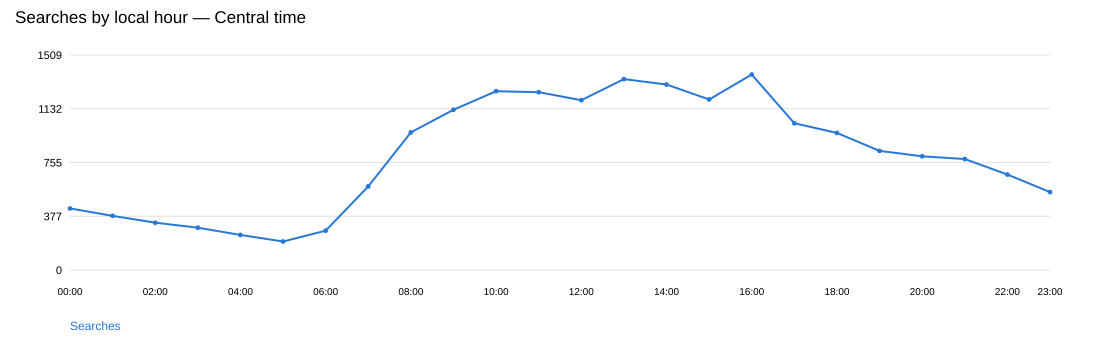

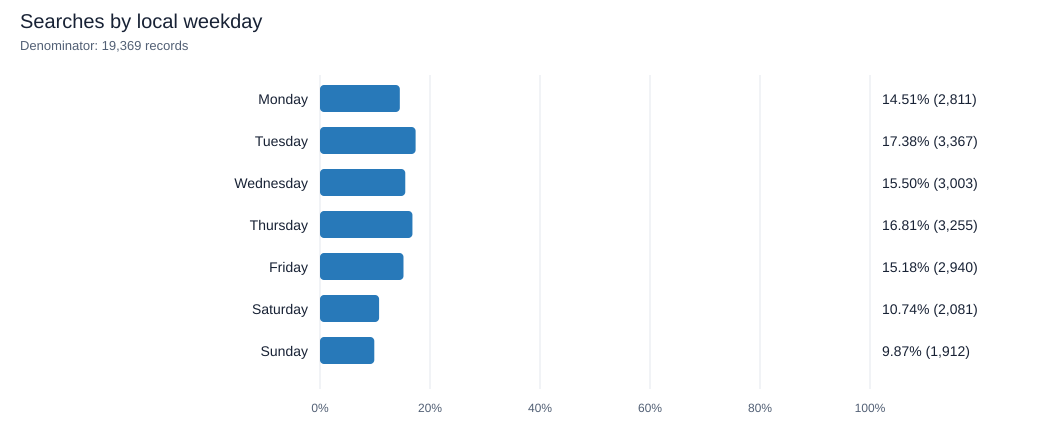

Group,Records,Percent
Monday,"2,811",14.51%
Tuesday,"3,367",17.38%
Wednesday,"3,003",15.50%
Thursday,"3,255",16.81%
Friday,"2,940",15.18%
Saturday,"2,081",10.74%
Sunday,"1,912",9.87%


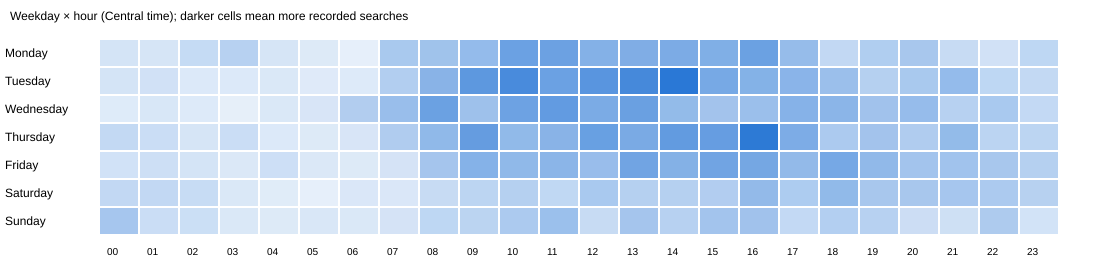

In [8]:
hour_counts=Counter(r['_time'].hour for r in records)
weekday_counts=Counter(r['_time'].weekday() for r in records)
series_chart_plain({'Searches':{f'{h:02d}:00':hour_counts[h] for h in range(24)}}, 'Searches by local hour — Central time', interpretation='The concentration outside overnight hours may reflect follow-up investigations and other work done during daytime or evening shifts. The logs cannot distinguish staffing effects from changes in search demand.')
weekdays=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
percent_chart_plain({d:weekday_counts[i] for i,d in enumerate(weekdays)},'Searches by local weekday',total, interpretation='Lower weekend totals may reflect investigative work concentrated in the normal workweek. Uneven audit coverage could also contribute, so the pattern does not establish why officers searched less on weekends.')
heat=Counter((r['_time'].weekday(),r['_time'].hour) for r in records)
parts=['<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 1100 270" role="img" aria-label="Weekday by local hour search counts" style="width:100%;max-width:1100px;background:white;font-family:Arial"><text x="10" y="20">Weekday × hour (Central time); darker cells mean more recorded searches</text>']
for d in range(7):
    parts.append(f'<text x="5" y="{57+d*28}" font-size="12">{weekdays[d]}</text>')
    for h in range(24):
        value=heat[d,h]; opacity=.08+.92*value/max(heat.values())
        parts.append(f'<rect x="{100+h*40}" y="{40+d*28}" width="38" height="26" fill="#2a78d6" fill-opacity="{opacity}"><title>{weekdays[d]} {h:02d}:00: {value:,} searches</title></rect>')
for h in range(24): parts.append(f'<text x="{107+h*40}" y="255" font-size="10">{h:02d}</text>')
display(SVG(''.join(parts)+'</svg>'))
display(HTML('<p><em>Possible explanation:</em> The darker weekday daytime cells may reflect searches conducted as part of scheduled investigative work. The quieter overnight and weekend cells suggest a workweek pattern, though coverage and staffing could both influence it.</p>'))
night=sum(hour_counts[h] for h in list(range(6))+[22,23])
print(f"22:00–05:59 Central: {night:,} searches ({night/total:.1%}); busiest hour: {hour_counts.most_common(1)[0][0]:02d}:00.")


## Conclusion

In [9]:
# Run independently, including after a kernel restart.
from collections import Counter
from html import escape
from IPython.display import HTML, display
from categorized_output.memphis_visuals import load_analysis_data

def display_memphis_conclusion():
    _, _, _, summary_records, _ = load_analysis_data()
    if not summary_records:
        display(HTML('<p>No valid Memphis searches are available.</p>'))
        return
    count = len(summary_records)
    reasoned_records = [r for r in summary_records if r['reason'].strip()]
    categories = Counter(r['_category'] for r in reasoned_records)
    first_date, last_date = summary_records[0]['_time'], summary_records[-1]['_time']
    weekday_totals = Counter(r['_time'].weekday() for r in summary_records)
    weekend_count = weekday_totals[5] + weekday_totals[6]
    overnight_count = sum(r['_time'].hour >= 22 or r['_time'].hour < 6 for r in summary_records)
    weekdays = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
    busiest = weekdays[max(range(7), key=lambda d: weekday_totals[d])]
    quietest = weekdays[min(range(7), key=lambda d: weekday_totals[d])]
    if categories:
        largest, largest_count = categories.most_common(1)[0]
        reason_summary = (
            f'<strong>{escape(largest)}</strong> is the largest recorded reason category '
            f'({largest_count/len(reasoned_records):.1%} of nonblank entries). '
            'A reason is usually present, but broad labels such as “investigation” leave the specific purpose unclear.'
        )
    else:
        reason_summary = 'No nonblank reasons are recorded.'
    display(HTML(
        f'<p>The Memphis records contain <strong>{count:,} candidate-deduplicated searches</strong> '
        f'from {first_date:%B %Y} to {last_date:%B %Y}. {reason_summary}</p>'
        f'<p><strong>Searches are less common on weekends.</strong> Saturday and Sunday account for '
        f'{weekend_count:,} searches ({weekend_count/count:.1%}), below the 28.6% expected if activity were evenly '
        f'distributed across all seven days. {busiest} has the most recorded searches and {quietest} the fewest, '
        'giving the logs a clear workweek rhythm.</p>'
        f'<p>Overnight activity is a smaller part of the picture: {overnight_count/count:.1%} of searches occur '
        f'from 22:00–05:59 Central. Only {(count-len(reasoned_records))/count:.1%} lack a recorded reason after '
        'candidate deduplication, though having text does not necessarily mean having a detailed explanation. '
        'These patterns describe the audits available here; uneven coverage limits what they reveal about all department activity.</p>'
    ))

display_memphis_conclusion()
